In [ ]:
import deep_models.config as c
from deep_models.data import load_folds, make_splits, S00MILDataset
from torch.utils.data import DataLoader
from deep_models.vae import SparseConvVAE
from deep_models.vae_train import init_model, fit, plot_history

In [ ]:
split_k = 7

In [ ]:
developamental_folds = load_folds(c.dev_path)
_, train_idx, val_idx, test_idx = next(split for split in make_splits(developamental_folds) if split[0] == split_k)
print(f"train={len(train_idx)}  val={len(val_idx)}  test={len(test_idx)}")

train=1085  val=132  test=136


In [4]:
train_ds = S00MILDataset(train_idx, max_instances=150, train=True)
val_ds   = S00MILDataset(val_idx,   max_instances=150, train=False)

train_loader = DataLoader(train_ds, batch_size=10, shuffle=True,  num_workers=2, pin_memory=True)
val_loader   = DataLoader(val_ds,   batch_size=10, shuffle=False, num_workers=2, pin_memory=True)

# Build & initialize model

In [ ]:
model = SparseConvVAE(latent=64, alpha=0.1).to(c.device)
init_model(model, train_loader)

SparseConvVAE(
  (encoder): Sequential(
    (0): Conv2d(5, 16, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(16, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    (3): ReLU()
    (4): Conv2d(32, 64, kernel_size=(5, 5), stride=(1, 1))
    (5): ReLU()
    (6): Flatten(start_dim=1, end_dim=-1)
  )
  (fc_mu): Linear(in_features=64, out_features=64, bias=True)
  (fc_logvar): Linear(in_features=64, out_features=64, bias=True)
  (fc): Linear(in_features=64, out_features=64, bias=True)
  (decoder): Sequential(
    (0): ConvTranspose2d(64, 32, kernel_size=(5, 5), stride=(1, 1))
    (1): ReLU()
    (2): ConvTranspose2d(32, 16, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    (3): ReLU()
    (4): ConvTranspose2d(16, 5, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
  )
  (fc_gamma): Linear(in_features=64, out_features=64, bias=True)
)

# Train the model & save the best epoch's version

In [ ]:
history = fit(model,
              train_loader,
              val_loader,
              epochs=150,
              lr=1e-3,
              beta_max=5e-4,
              anneal_start=50,
              anneal_epochs=50,
              ckpt_path=f"best_svae_split{split_k}.pt")

epoch   1/150  beta 0.00e+00  train 0.7736  val 0.7144  recon 0.7144  MSE 0.00053  KL 135.12  R2 0.074
epoch   2/150  beta 0.00e+00  train 0.6438  val 0.5683  recon 0.5683  MSE 0.00042  KL 322.17  R2 0.264
epoch   3/150  beta 0.00e+00  train 0.5009  val 0.4626  recon 0.4626  MSE 0.00034  KL 410.65  R2 0.401
epoch   4/150  beta 0.00e+00  train 0.4023  val 0.3657  recon 0.3657  MSE 0.00027  KL 463.66  R2 0.526
epoch   5/150  beta 0.00e+00  train 0.3472  val 0.3351  recon 0.3351  MSE 0.00025  KL 468.35  R2 0.566
epoch   6/150  beta 0.00e+00  train 0.3242  val 0.3164  recon 0.3164  MSE 0.00023  KL 474.19  R2 0.590
epoch   7/150  beta 0.00e+00  train 0.3092  val 0.3028  recon 0.3028  MSE 0.00022  KL 478.76  R2 0.608
epoch   8/150  beta 0.00e+00  train 0.2940  val 0.2904  recon 0.2904  MSE 0.00021  KL 486.39  R2 0.624
epoch   9/150  beta 0.00e+00  train 0.2828  val 0.2794  recon 0.2794  MSE 0.00021  KL 491.47  R2 0.638
epoch  10/150  beta 0.00e+00  train 0.2737  val 0.2716  recon 0.2716  MSE

# Evaluate training history

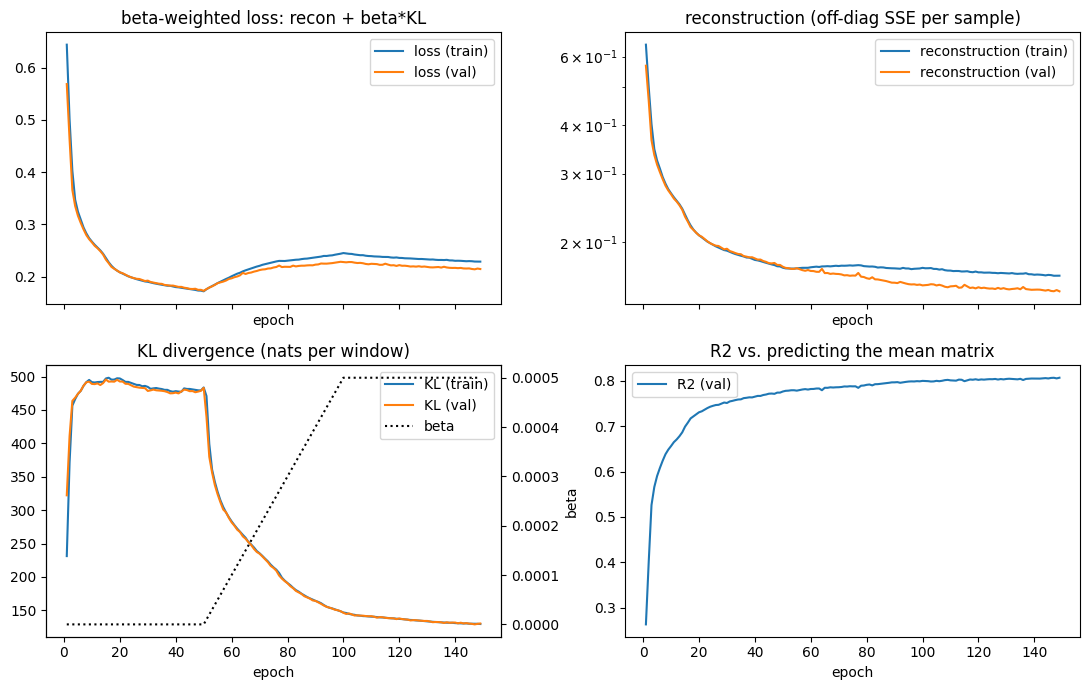

In [7]:
g = plot_history(history, skip=1)
g.show()